# What is the probability of drawing at least one wild card AND a skip card in a standard 7-hand deck in UNO.

To find the **joint probability** in this scenario, I will be using the **random process** to simulate every possible outcome when you draw 7 cards in UNO. For example, in one round , you could draw 2 wild cards but no skip cards. The **compound event** of this scenario would be **dependent** because if you draw a wild card, the chances of the next card being a skip card would increase because the number of cards in the deck is decreased, meaning that one outcome changed the probability of another outcome. If I call the wild card "A" and the skip card "B", I could use the **joint probability** formula, P(AandB)=P(A)*P(B) to evaluate whether this event is independent or dependent. The events "A" and "B" are **not mutually exclusive** because if you were to draw 2 cards at the same time, there is still a chance of getting both a wild card and a skip card, meaning it could potentially exist at the same time. 

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Theoretical Probability Analysis: 

### 1. Overall Deck

In [2]:
deck = np.array(['Wild'] * 8 + ['Skip'] * 8 + ['Other'] * 92)
hands = [np.random.choice(deck, size=7, replace=False) for _ in range(100000)]
df = pd.DataFrame(hands)

### 2. Has Wild or Skip Card

In [3]:
wild = (df == 'Wild').any(axis=1)
skip = (df == 'Skip').any(axis=1)

### 3. Calculate percentages of having both

In [4]:
probability = (wild & skip).mean()

### Evaluation: 

In [6]:
print("Chance of drawing both:", probability * 100 , "%")

Chance of drawing both: 16.467000000000002 %


## Empirical Probability Analysis:

### 1. Set up cards to be at random

In [7]:
trials = 1000
rolls = np.random.randint(1, 7, size=trials)
df = pd.DataFrame({'roll': rolls})

### 2. Select Cards at random

In [8]:
empirical = (df['roll'] == 6).mean()

### Evaluation: 

In [15]:
print("Empirical Probability:", empirical * 100,"%" )

Empirical Probability: 15.299999999999999 %


## Visual:

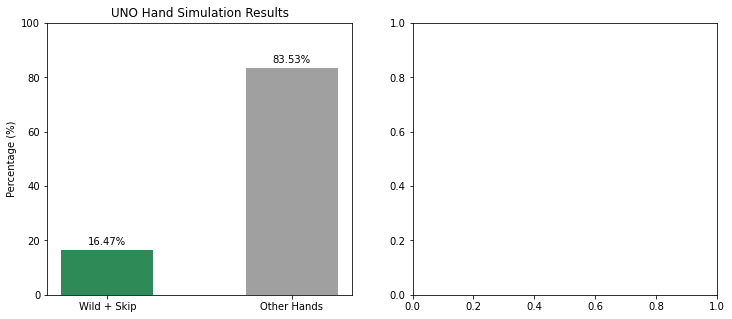

In [13]:
fig, (ax1 , ax2) = plt.subplots(1, 2, figsize=(12, 5))

uno_outcomes = [(wild & skip).mean() * 100, (1 - (wild & skip).mean()) * 100]
ax1.bar(['Wild + Skip', 'Other Hands'], uno_outcomes, color=['#2E8B57', '#A0A0A0'], width=0.5)
ax1.set_title('UNO Hand Simulation Results')
ax1.set_ylabel('Percentage (%)')
ax1.set_ylim(0, 100)
for bar in ax1.patches:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{bar.get_height():.2f}%", ha='center')


# Conclusion:

After calculating the joint probability of drawing atleast one wild card and a skip card in a standard 7 hand deck in UNO, I found both the theoretical and empirical probabilities of this scenerio. The theoretical probability has results based on the number of both cards and the total number of cards to find that theoretically the chance of drawing both is roughly around 16.5%. However, a theoretical probability is more of an assumption rather than actual results. The empirical probability has results based on actual trials drawn at random. After running 1000 trials, the empirical probability of drawing both cards at the same time was about 15.3%. These results are slighty similar to each other but not quite the same, showing that the theoretical probability is more of a guess rather than actual results while empirical probability has results based on actual trial, making it a bit more accurate, but the results will be different everytime. 